Membership ACLO Sheets

In [4]:
import pandas as pd

# Load the CSV files
file_paths = {
    "ACLO_2020_2021": "Data/Cardholders/Membership Aclo_sheet_ACLO  2020-2021.csv",
    "ACLO_2021_2022": "Data/Cardholders/Membership Aclo_sheet_ACLO 2021-2022.csv",
    "Fitness_2020_2021": "Data/Cardholders/Membership Aclo_sheet_Fitness  2020-2021.csv",
    "Fitness_2021_2022": "Data/Cardholders/Membership Aclo_sheet_Fitness 2021-2022 .csv"
}

# Load each CSV into a dictionary of DataFrames
dataframes = {name: pd.read_csv(path) for name, path in file_paths.items()}

Descriptive Statistics Calculation

In [5]:
# Define a function to calculate basic descriptive statistics
def descriptive_statistics(df, name):
    stats = {
        "Dataset": name,
        "Total Entries": len(df),
        "Male Members": df["Geslacht Man"].notna().sum(),
        "Female Members": df["Geslacht vrouw"].notna().sum(),
        "Membership Type": df["Omschrijving"].unique()[0] if "Omschrijving" in df.columns else "Unknown"
    }
    return stats
    
descriptive_stats = pd.DataFrame([descriptive_statistics(df, name) for name, df in dataframes.items()])
print(descriptive_stats)

             Dataset  Total Entries  Male Members  Female Members  \
0     ACLO_2020_2021          13952          6229            7520   
1     ACLO_2021_2022          16523          7030            8905   
2  Fitness_2020_2021            984           687             294   
3  Fitness_2021_2022           1371           957             400   

          Membership Type  
0     ACLO Card 2020-2021  
1     ACLO Card 2021-2022  
2  Fitness Card 2020-2021  
3  Fitness Card 2021/2022  


Correlation Matrix Calculation

In [6]:
# Convert 'Geslacht Man' and 'Geslacht vrouw' columns to binary (1 if present, 0 if absent)
for name, df in dataframes.items():
    df["Geslacht Man"] = df["Geslacht Man"].notna().astype(int)
    df["Geslacht vrouw"] = df["Geslacht vrouw"].notna().astype(int)

# Calculate correlation matrix for each dataset
correlation_matrices = {name: df[["Klant nr", "Geslacht Man", "Geslacht vrouw"]].corr() for name, df in dataframes.items()}
for name, matrix in correlation_matrices.items():
    print(f"Correlation matrix for {name}:\n{matrix}\n")

Correlation matrix for ACLO_2020_2021:
                Klant nr  Geslacht Man  Geslacht vrouw
Klant nr        1.000000     -0.070534        0.049525
Geslacht Man   -0.070534      1.000000       -0.971073
Geslacht vrouw  0.049525     -0.971073        1.000000

Correlation matrix for ACLO_2021_2022:
                Klant nr  Geslacht Man  Geslacht vrouw
Klant nr        1.000000     -0.077534        0.020314
Geslacht Man   -0.077534      1.000000       -0.930406
Geslacht vrouw  0.020314     -0.930406        1.000000

Correlation matrix for Fitness_2020_2021:
                Klant nr  Geslacht Man  Geslacht vrouw
Klant nr        1.000000     -0.117095        0.112172
Geslacht Man   -0.117095      1.000000       -0.992771
Geslacht vrouw  0.112172     -0.992771        1.000000

Correlation matrix for Fitness_2021_2022:
                Klant nr  Geslacht Man  Geslacht vrouw
Klant nr        1.000000     -0.037270        0.030787
Geslacht Man   -0.037270      1.000000       -0.975835
Geslacht v

Gender Distribution Visualization

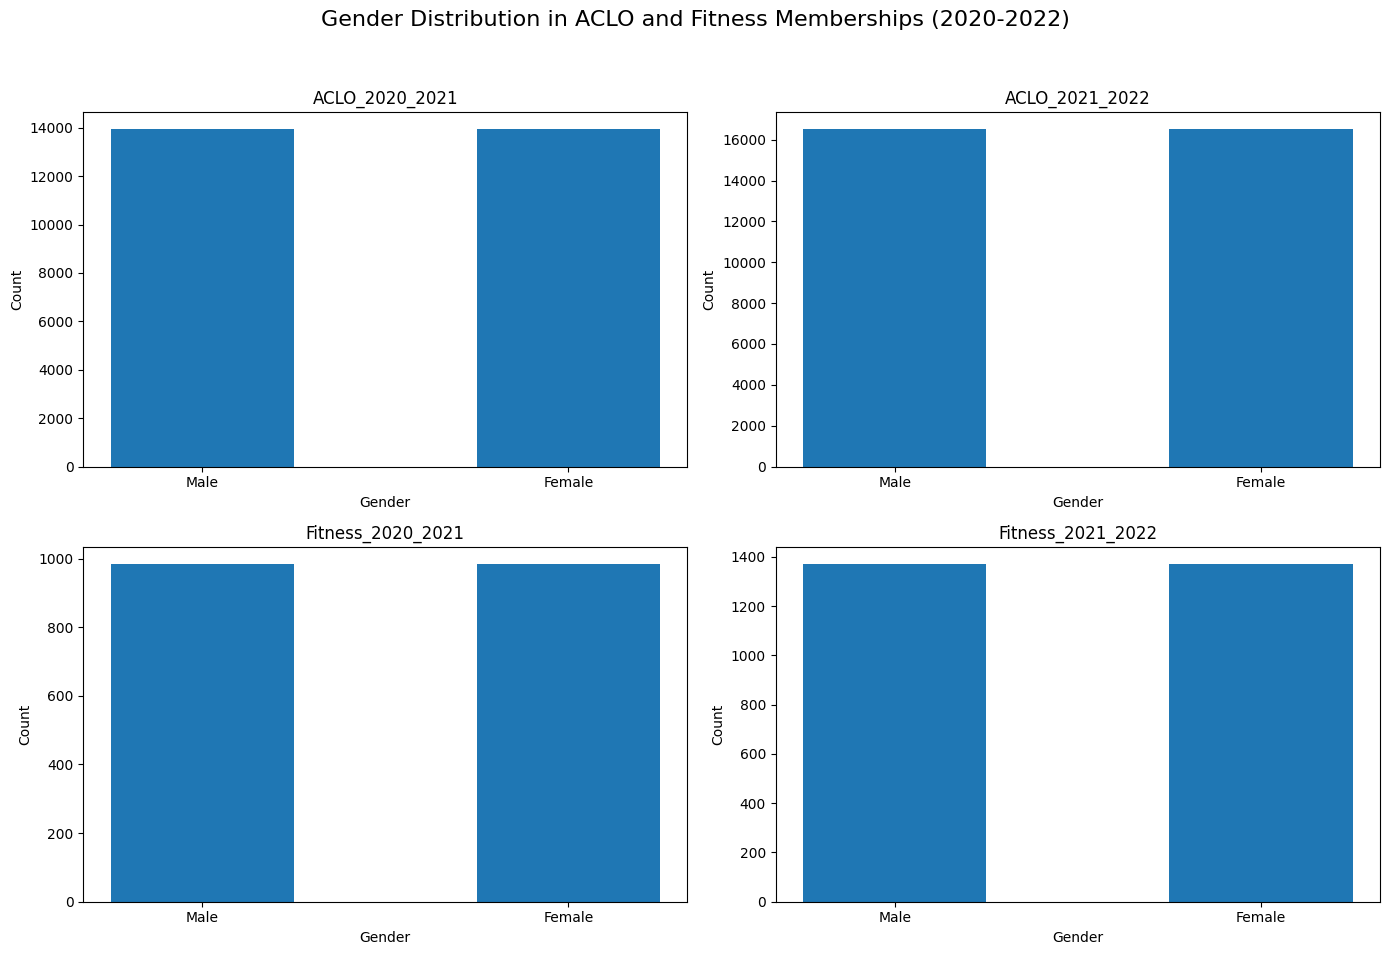

In [7]:
import matplotlib.pyplot as plt

# Visualize gender distribution in each dataset
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Gender Distribution in ACLO and Fitness Memberships (2020-2022)', fontsize=16)

for ax, (name, df) in zip(axes.flatten(), dataframes.items()):
    male_count = df["Geslacht Man"].notna().sum()
    female_count = df["Geslacht vrouw"].notna().sum()
    
    ax.bar(['Male', 'Female'], [male_count, female_count], width=0.5)
    ax.set_title(name)
    ax.set_xlabel('Gender')
    ax.set_ylabel('Count')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

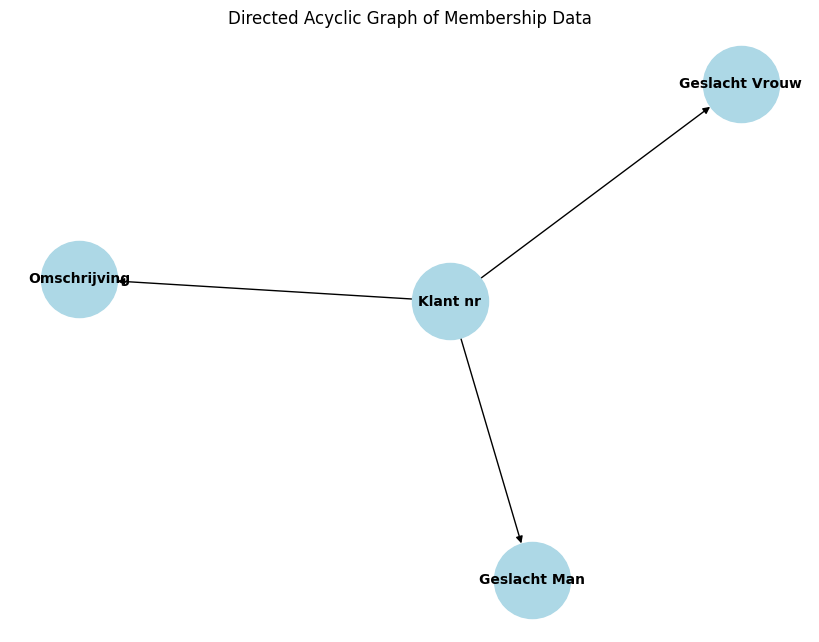

In [8]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a Directed Acyclic Graph
G = nx.DiGraph()

# Define nodes for the graph
nodes = ["Klant nr", "Geslacht Man", "Geslacht Vrouw", "Omschrijving"]

# Add nodes to the graph
G.add_nodes_from(nodes)

# Define edges (relationships)
edges = [
    ("Klant nr", "Geslacht Man"),    # Klant nr determines gender status (man)
    ("Klant nr", "Geslacht Vrouw"),  # Klant nr determines gender status (vrouw)
    ("Klant nr", "Omschrijving"),    # Klant nr is associated with the type of membership
]

# Add edges to the graph
G.add_edges_from(edges)

# Draw the graph
plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G)  # Define layout for better visualization
nx.draw(G, pos, with_labels=True, node_size=3000, font_size=10, font_weight='bold', node_color="lightblue", arrows=True)
plt.title("Directed Acyclic Graph of Membership Data")
plt.show()

Check-in Times Sheets 

In [ ]:
file_paths = [
    'Data/Check-in times/Check-in-times_sheet_2017-2018.csv',
    'Data/Check-in times/Check-in-times_sheet_2018-2019.csv',
    'Data/Check-in times/Check-in-times_sheet_2019-2020.csv',
    'Data/Check-in times/Check-in-times_sheet_2020-2021.csv',
    'Data/Check-in times/Check-in-times_sheet_2021-.csv'
]

data_frames = [pd.read_csv(file) for file in file_paths]

FileNotFoundError: [Errno 2] No such file or directory: '/Data/Check-in times/Check-in-times_sheet_2017-2018.csv'

Descriptive Statistics

In [ ]:
# Concatenate all data frames into a single one for easier analysis
combined_data = pd.concat(data_frames, ignore_index=True)

# Display the column data types and summary statistics
combined_data_info = combined_data.info()
combined_data_describe = combined_data.describe(include='all')

# Showing initial descriptive statistics for further insights
combined_data_info, combined_data_describe

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380785 entries, 0 to 380784
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   Klant nr      380785 non-null  int64 
 1   Lid id        102827 non-null  object
 2   Geslacht      380785 non-null  object
 3   Abo bezoek    373011 non-null  object
 4   Incheckdatum  380785 non-null  object
 5   Lid id        253005 non-null  object
dtypes: int64(1), object(5)
memory usage: 17.4+ MB


(None,
              Klant nr     Lid id  Geslacht              Abo bezoek  \
 count   380785.000000      102827   380785                  373011   
 unique            NaN          34        3                      48   
 top               NaN  RUG               M  Fitness Card 2017-2018   
 freq              NaN       65407   280767                   86417   
 mean    191590.238121         NaN      NaN                     NaN   
 std      28360.215007         NaN      NaN                     NaN   
 min         26.000000         NaN      NaN                     NaN   
 25%     183541.000000         NaN      NaN                     NaN   
 50%     196651.000000         NaN      NaN                     NaN   
 75%     207474.000000         NaN      NaN                     NaN   
 max     235293.000000         NaN      NaN                     NaN   
 
                Incheckdatum      Lid id  
 count                380785      253005  
 unique               354139         110  
 top     2

Visualization Check-in Times

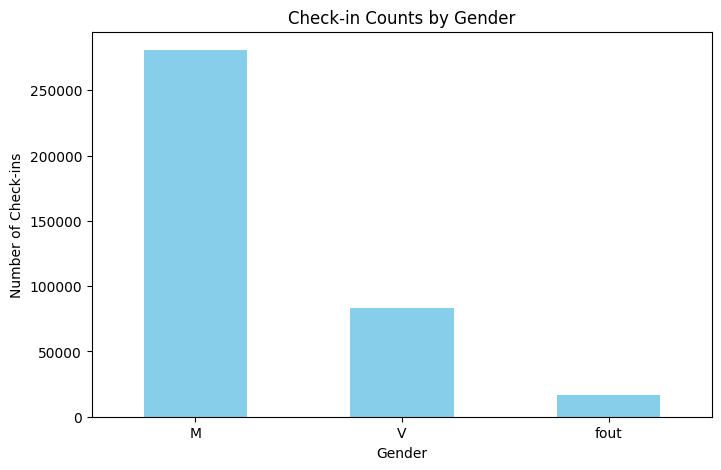

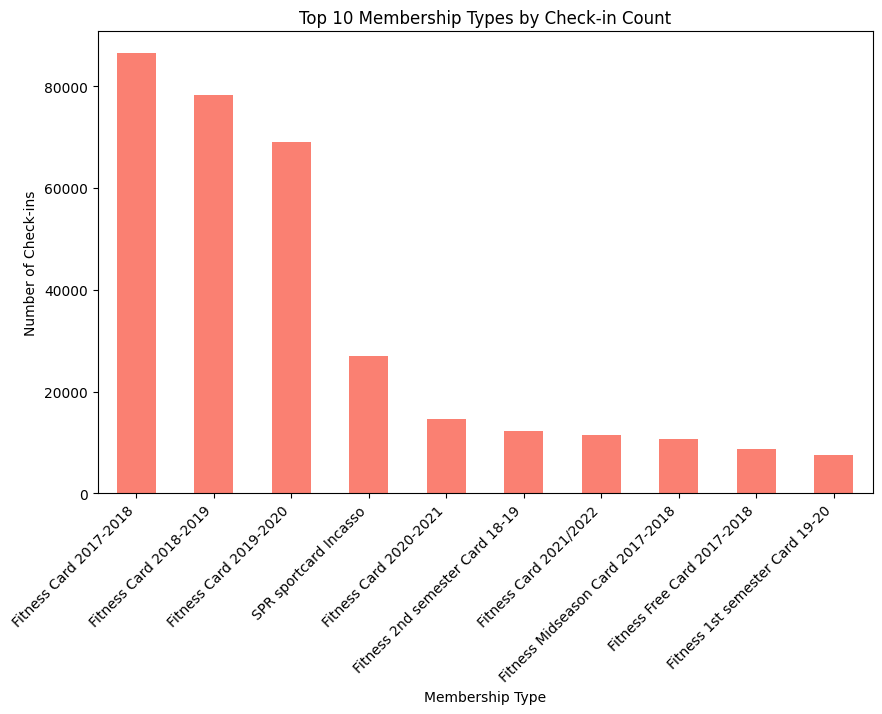

<Figure size 1200x600 with 0 Axes>

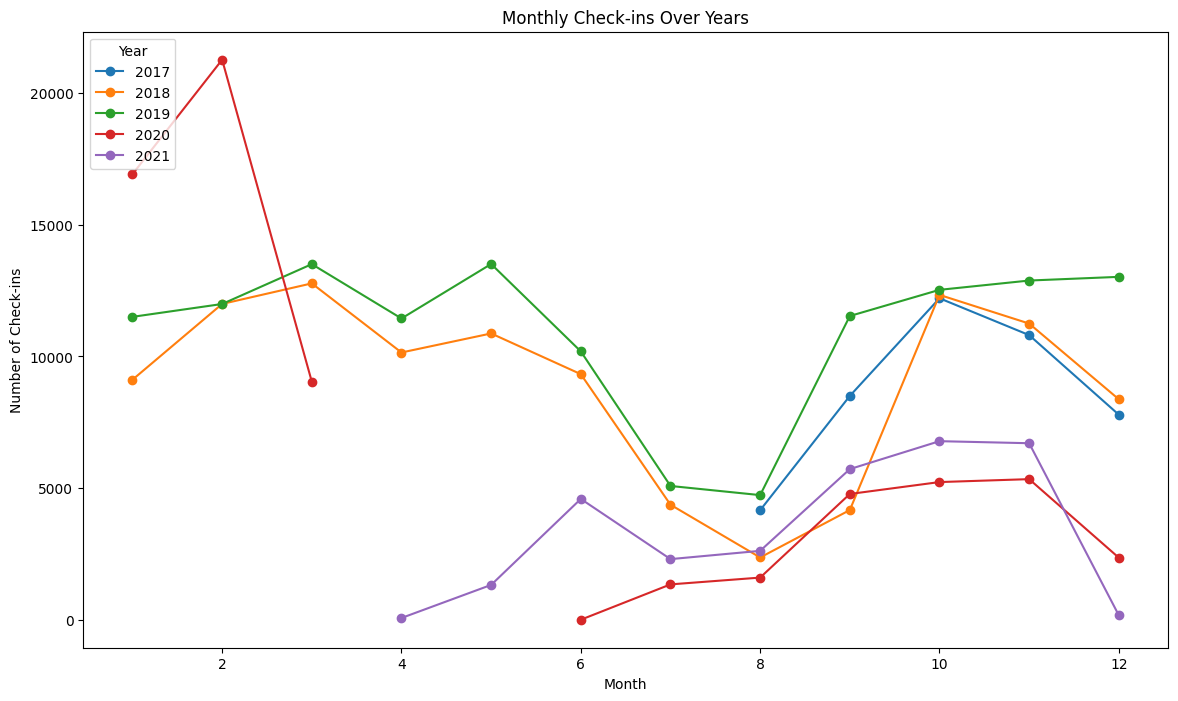

In [ ]:
# Visualization 1: Check-in counts by gender
gender_checkin_counts = combined_data['Geslacht'].value_counts()

plt.figure(figsize=(8, 5))
gender_checkin_counts.plot(kind='bar', color='skyblue')
plt.title('Check-in Counts by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Check-ins')
plt.xticks(rotation=0)
plt.show()

# Visualization 2: Check-in counts by membership type (Top 10 membership types)
plt.figure(figsize=(10, 6))
membership_counts = combined_data['Abo bezoek'].value_counts().head(10)
membership_counts.plot(kind='bar', color='salmon')
plt.title('Top 10 Membership Types by Check-in Count')
plt.xlabel('Membership Type')
plt.ylabel('Number of Check-ins')
plt.xticks(rotation=45, ha='right')
plt.show()

# Visualization 3: Monthly check-in pattern (captured earlier, shown again here for continuity)
combined_data['Incheckdatum'] = pd.to_datetime(combined_data['Incheckdatum'], errors='coerce')
combined_data['Year'] = combined_data['Incheckdatum'].dt.year
combined_data['Month'] = combined_data['Incheckdatum'].dt.month

# Group data by year and month to view check-in patterns over time
monthly_checkins = combined_data.groupby(['Year', 'Month']).size().unstack(level=0)

# Plot monthly check-ins to identify trends over the years
plt.figure(figsize=(12, 6))
monthly_checkins.plot(kind='line', marker='o', figsize=(14, 8))
plt.title('Monthly Check-ins Over Years')
plt.xlabel('Month')
plt.ylabel('Number of Check-ins')
plt.legend(title='Year', loc='upper left')
plt.show()

Directed Acyclic Graph

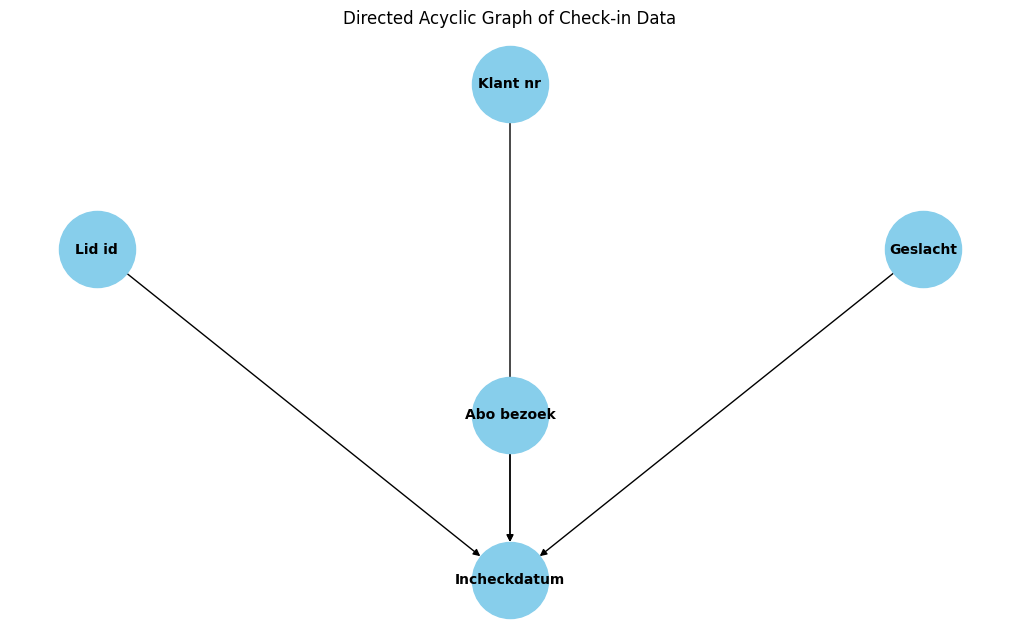

In [ ]:
# Initialize a directed graph
G = nx.DiGraph()

# Define nodes and edges based on the dataset structure
nodes = ["Klant nr", "Lid id", "Geslacht", "Abo bezoek", "Incheckdatum"]
edges = [("Klant nr", "Incheckdatum"), ("Lid id", "Incheckdatum"), 
         ("Geslacht", "Incheckdatum"), ("Abo bezoek", "Incheckdatum")]

# Add nodes and edges to the graph
G.add_nodes_from(nodes)
G.add_edges_from(edges)

# Draw the graph
plt.figure(figsize=(10, 6))
pos = {
    "Klant nr": (0, 1), "Lid id": (-1, 0), "Geslacht": (1, 0),
    "Abo bezoek": (0, -1), "Incheckdatum": (0, -2)
}
nx.draw(G, pos, with_labels=True, node_size=3000, node_color="skyblue", font_size=10, font_weight="bold", arrows=True)
plt.title("Directed Acyclic Graph of Check-in Data")
plt.show()

Predictive Modelling

Data Cleaning

We merge the two datasets using the Klant nr column to combine relevant information about individuals and their fitness usage.

In [ ]:
import glob

cardholders_files = glob.glob("../Data/Cardholders/*.csv")

# Read each CSV file into a DataFrame and store it in a list
cardholders_dfs = [pd.read_csv(file) for file in cardholders_files]

# Merge all DataFrames in the list
cardholders = pd.concat(cardholders_dfs, ignore_index=True)

cardholders_files = glob.glob("../Data/Check-in times/*.csv")
checkin_times_dfs = [pd.read_csv(file) for file in cardholders_files]
checkin_times = pd.concat(checkin_times_dfs, ignore_index=True)

# Merge the datasets on the 'Klant nr' column
merged_df = pd.merge(cardholders, checkin_times, on='Klant nr', how='inner')

# Display the merged DataFrame info
# checkin_times.info()
# print(merged_df.head())

In [ ]:
import numpy as np

# Create a new 'Gender' column based on the existing columns
merged_df['Geslacht_'] = np.where(merged_df['Geslacht Man'].notna(), 'Man',
                       np.where(merged_df['Geslacht vrouw'].notna(), 'Vrouw',
                                merged_df['Geslacht']))

# Drop the old gender-related columns if no longer needed
merged_df = merged_df.drop(columns=['Geslacht Man', 'Geslacht vrouw', 'Geslacht'])

In [ ]:
# Convert the 'Incheckdatum' column to datetime format
merged_df['Incheckdatum'] = pd.to_datetime(merged_df['Incheckdatum'], errors='coerce')

# Extract additional date-related features
merged_df['Year'] = merged_df['Incheckdatum'].dt.year
merged_df['Month'] = merged_df['Incheckdatum'].dt.month
merged_df['Day'] = merged_df['Incheckdatum'].dt.day
merged_df['Weekday'] = merged_df['Incheckdatum'].dt.day_name()
merged_df['Is_Weekend'] = merged_df['Weekday'].isin(['Saturday', 'Sunday'])

# Display the updated dataset with the new columns
# print(merged_df[['Incheckdatum', 'Year', 'Month', 'Day', 'Weekday', 'Is_Weekend']].head())


Code to Mark Exam Periods

In [ ]:
import pandas as pd
import numpy as np

# Define exam periods as a dictionary of academic years and date ranges
exam_periods = {
    '2017-2018': [
        ('2017-10-30', '2017-11-10'),
        ('2018-01-14', '2018-02-01'),
        ('2018-03-25', '2018-04-12'),
        ('2018-06-11', '2018-06-29'),
        ('2018-07-02', '2018-07-13')
    ],
    '2018-2019': [
        ('2018-10-29', '2018-11-09'),
        ('2019-01-15', '2019-02-02'),
        ('2019-03-26', '2019-04-13'),
        ('2019-06-11', '2019-06-28')
    ],
    '2019-2020': [
        ('2019-10-28', '2019-11-08'),
        ('2020-01-13', '2020-01-31'),
        ('2020-03-23', '2020-03-31'),
        ('2020-06-08', '2020-06-10')
    ],
    '2020-2021': [
        ('2020-08-17', '2020-08-28'),
        ('2020-10-26', '2020-11-06'),
        ('2021-01-11', '2021-01-29'),
        ('2021-03-22', '2021-04-09'),
        ('2021-06-07', '2021-06-25')
    ],
    '2021-2022': [
        ('2021-11-01', '2021-11-12'),
        ('2022-01-17', '2022-02-04'),
        ('2022-03-28', '2022-04-14'),
        ('2022-06-13', '2022-07-01')
    ]
}

# Ensure 'Incheckdatum' is in datetime format
merged_df['Incheckdatum'] = pd.to_datetime(merged_df['Incheckdatum'], errors='coerce')

# Precompute all exam period date ranges as pandas Timestamp objects
exam_period_ranges = []
for periods in exam_periods.values():
    for start, end in periods:
        exam_period_ranges.append((pd.Timestamp(start), pd.Timestamp(end)))

# Convert the list of tuples into a DataFrame
exam_period_df = pd.DataFrame(exam_period_ranges, columns=['Start', 'End'])

# Function to check if dates are within any exam period
def check_exam_period(dates):
    # Initialize a boolean Series with False
    is_exam = pd.Series(False, index=dates.index)
    for _, row in exam_period_df.iterrows():
        # Update the Series where the date falls within an exam period
        is_exam |= (dates >= row['Start']) & (dates <= row['End'])
    return is_exam

# Apply the function to create the 'Exam_Period' column
merged_df['Exam_Period'] = check_exam_period(merged_df['Incheckdatum'])




In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Aggregate the data by date to get the number of visitors per day
daily_visitors = merged_df.groupby('Incheckdatum').size()

# Prepare the data for the models
# Convert dates to ordinal (integer) values for the model
X = np.array(daily_visitors.index.map(pd.Timestamp.toordinal)).reshape(-1, 1)
y = daily_visitors.values

# Models to compare
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

# Evaluate each model
results = {}
for model_name, model in models.items():
    # Train the model
    model.fit(X, y)
    
    # Make predictions
    y_pred = model.predict(X)
    
    # Evaluate the model
    r2 = r2_score(y, y_pred)
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    results[model_name] = {"R² Score": r2, "RMSE": rmse}
    
   

# Display model evaluation results
for model_name, metrics in results.items():
    print(f"{model_name}:")
    print(f"  R² Score: {metrics['R² Score']:.4f}")
    print(f"  RMSE: {metrics['RMSE']:.4f}")


Linear Regression:
  R² Score: 0.0320
  RMSE: 1.3890
Decision Tree:
  R² Score: 0.2172
  RMSE: 1.2491
Random Forest:
  R² Score: 0.2171
  RMSE: 1.2491


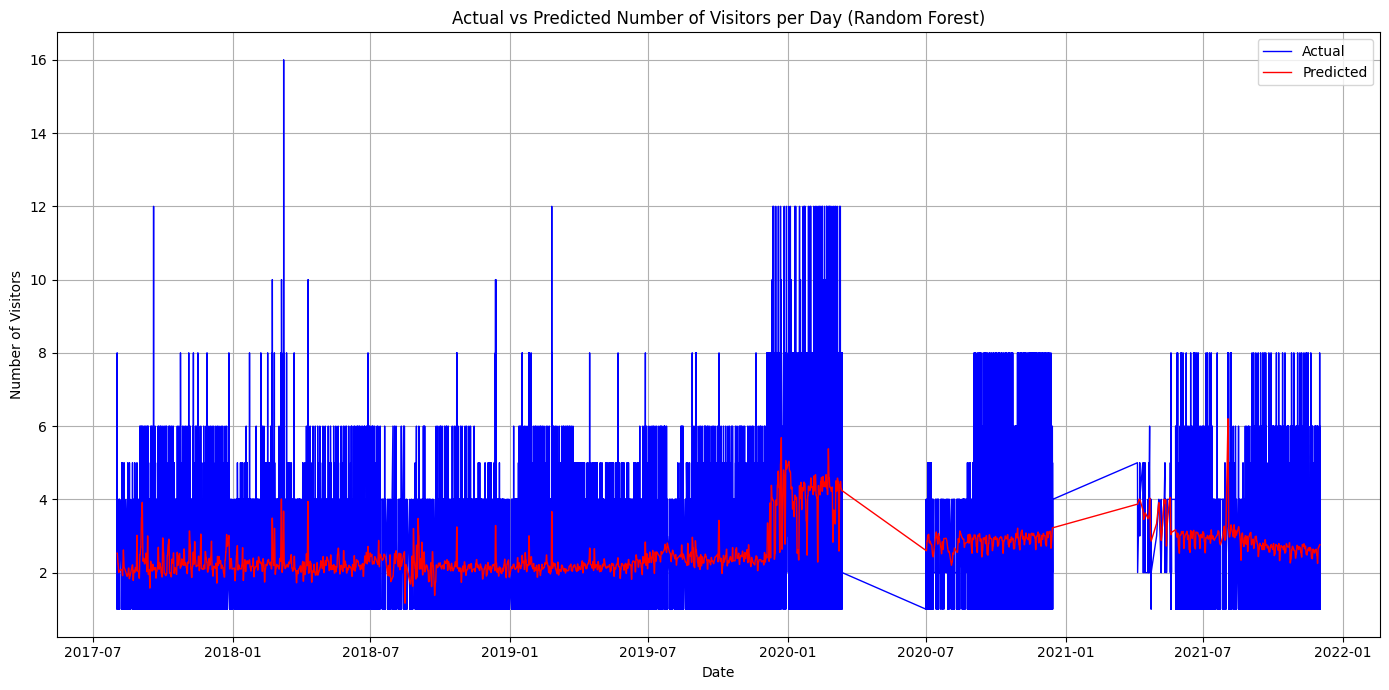

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Aggregate the data by date to get the number of visitors per day
daily_visitors = merged_df.groupby('Incheckdatum').size()

# Prepare the data for the Random Forest model
# Convert dates to ordinal (integer) values for the model
X = np.array(daily_visitors.index.map(pd.Timestamp.toordinal)).reshape(-1, 1)
y = daily_visitors.values

# Train a Random Forest Regressor model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X, y)

# Predict values using the trained model
y_pred = rf_model.predict(X)

# Plot both "actual" and "predicted" values in a zig-zag style
plt.figure(figsize=(14, 7))

# Plot the actual data in blue
plt.plot(daily_visitors.index, y, color='blue', linewidth=1, label='Actual')

# Plot the predicted data in red, closely following the actual data
plt.plot(daily_visitors.index, y_pred, color='red', linewidth=1, label='Predicted')

# Enhancements to match style
plt.title('Actual vs Predicted Number of Visitors per Day (Random Forest)')
plt.xlabel('Date')
plt.ylabel('Number of Visitors')
plt.legend(loc='best')
plt.grid(True)

# Show the plot
plt.tight_layout()
plt.show()